In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "changing_childhood.csv"

df = pd.read_csv(DATA_PATH, low_memory=False)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (58146, 32)

Column names:
['WP5', 'countrynew', 'wgt', 'EMP_2010', 'EMP_FTEMP', 'EMP_LFPR', 'EMP_WORK_HOURS', 'INCOME_5', 'WP10200', 'WP10202', 'WP12', 'WP1220', 'WP1219', 'WP1230RECODED', 'WP1233RECODED', 'WP16056', 'WP2319', 'WP30', 'WP3117', 'WP40', 'WP4657', 'WP1325', 'WP22827', 'WP22086', 'WP22087', 'WP22088', 'WP22089', 'WP22090', 'WP22091', 'WP22125', 'WP22826', 'WP22828']


,WP5,countrynew,wgt,EMP_2010,EMP_FTEMP,EMP_LFPR,EMP_WORK_HOURS,INCOME_5,WP10200,WP10202,...,WP22827,WP22086,WP22087,WP22088,WP22089,WP22090,WP22091,WP22125,WP22826,WP22828
0,2,Egypt,0.433316,6,NaN,0,NaN,4,2,2.0,...,2,1,1.0,1,1,1,2,1,1,1
1,2,Egypt,0.398746,1,1.0,1,3.0,1,1,NaN,...,2,1,1.0,1,1,1,1,1,1,1
2,2,Egypt,1.072377,1,1.0,1,5.0,4,1,NaN,...,3,8,3.0,2,2,2,2,2,3,8
3,2,Egypt,0.293731,6,NaN,0,NaN,5,2,2.0,...,2,2,2.0,1,1,1,3,1,1,2
4,2,Egypt,1.063580,2,0.0,1,4.0,3,2,1.0,...,1,2,1.0,1,1,1,2,1,3,2


In [2]:
quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

display(quality_report)

,data_type,missing_count,missing_percent,unique_values
WP5,int64,0,0.00,55
countrynew,object,0,0.00,55
wgt,float64,0,0.00,32584
EMP_2010,int64,0,0.00,6
EMP_FTEMP,float64,21286,36.61,2
EMP_LFPR,int64,0,0.00,2
EMP_WORK_HOURS,float64,25710,44.22,6
INCOME_5,int64,0,0.00,5
WP10200,int64,0,0.00,4
WP10202,float64,12685,21.82,4


In [3]:
print("Duplicate rows:", df.duplicated().sum())
print("Total rows:", len(df))

Duplicate rows: 3
Total rows: 58146


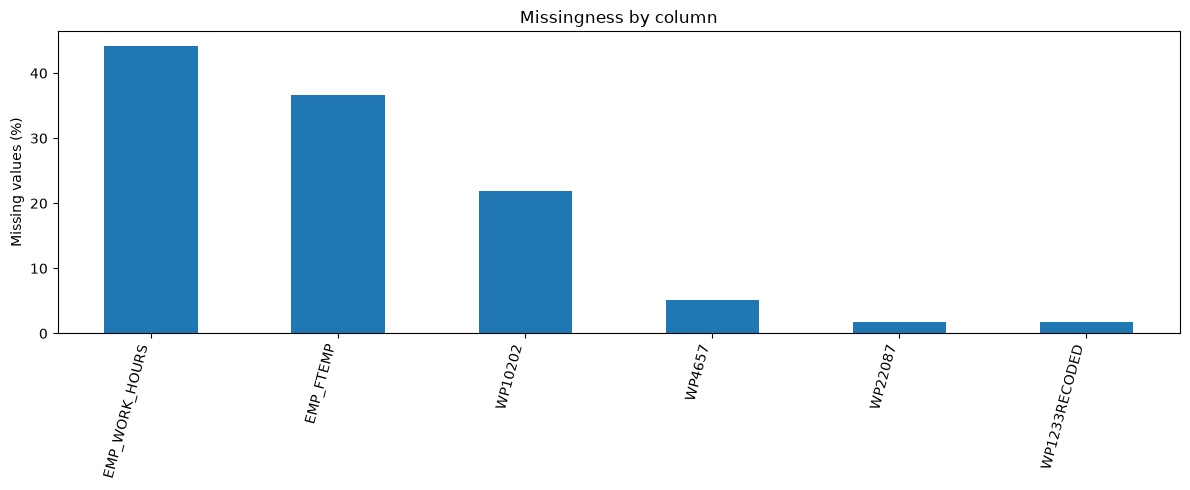

In [4]:
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

if missing.empty:
    print("No pandas-recognized missing values found.")
else:
    missing.plot(kind="bar", figsize=(12, 5))
    plt.ylabel("Missing values (%)")
    plt.title("Missingness by column")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()